Homework Reflection 6

1. What is a potential problem with computing the Marginal Treatment Effect simply by comparing each untreated item to its counterfactual and taking the maximum difference?  (Hint: think of statistics here.  Consider that only the most extreme item ends up being used to estimate the MTE.  That's not necessarily a bad thing; the MTE is supposed to come from the untreated item that will produce the maximum effect.  But there is nevertheless a problem.)
Possible answer: We are likely to find the item with the most extreme difference, which may be high simply due to randomness.
(Please explain / justify this answer, or give a different one if you can think of one.)

In [1]:
import numpy as np

def untreated_effects(seed, n=10_000):
    """Same tutoring world as Week 5, but generate BOTH potential outcomes for everyone."""
    rng = np.random.default_rng(seed)
    motivation = rng.normal(0, 1, n)
    tutoring   = (motivation + rng.normal(0, 1, n) > 0).astype(float)

    # Potential outcomes: same person, with and without tutoring (each with its own noise)
    study0 = 5     + rng.normal(0, 1, n)
    study1 = 5 + 3 + rng.normal(0, 1, n)
    y0 = 60 + 2 * study0 + 5 * motivation + rng.normal(0, 3, n)
    y1 = 60 + 2 * study1 + 5 * motivation + rng.normal(0, 3, n)

    return (y1 - y0)[tutoring == 0]           # individual effects for the untreated

d = untreated_effects(4)
print(f"Untreated students:          {d.size}")
print(f"True effect for EVERYONE:     6.00")
print(f"Mean estimated effect:        {d.mean():.2f}")
print(f"MAX estimated effect ('MTE'): {d.max():.2f}   <- the naive MTE")

# 1) The max is unstable: rerun the same world with different seeds
maxes = [untreated_effects(s).max() for s in range(200)]
print(f"\nMax across 200 reruns: mean {np.mean(maxes):.2f}, sd {np.std(maxes):.2f}, "
      f"range {min(maxes):.1f} - {max(maxes):.1f}")

# 2) The max grows with sample size even though the true effect never changes
for size in [100, 1_000, 10_000, 100_000]:
    print(f"n = {size:>7,}: average max = {np.mean([untreated_effects(s, size).max() for s in range(50)]):.2f}")

Untreated students:          4912
True effect for EVERYONE:     6.00
Mean estimated effect:        5.98
MAX estimated effect ('MTE'): 23.56   <- the naive MTE

Max across 200 reruns: mean 24.74, sd 1.77, range 21.4 - 29.9
n =     100: average max = 17.66
n =   1,000: average max = 21.90
n =  10,000: average max = 25.09
n = 100,000: average max = 27.20


The problem is that the maximum of many noisy estimates is a biased and unstable statistic. Each student's estimated effect, Y(1) − Y(0), equals their true effect plus random noise. When we take the maximum over thousands of students, we pick whoever had the most extreme noise draw, not necessarily the person with the largest true effect. This is the "winner's curse" (also called regression to the mean, or a multiple-comparisons problem): the more items we compare, the more likely one of them looks extreme purely by chance.

I demonstrated this with the tutoring model from Week 5, where tutoring raises every student's score by exactly 6 points, so the true marginal treatment effect is 6. Yet the largest estimated effect among 4,912 untreated students was 23.6, almost four times the truth. Across 200 reruns, the maximum ranged from 21.4 to 29.9, so the estimate also has high variance. The maximum also keeps growing with sample size (about 17.7 at n = 100 and 27.2 at n = 100,000) even though the true effect never changes. A useful estimator should converge to the true value as we collect more data; the maximum moves away from it.

So the naive MTE is driven by a single noisy observation. It is biased upward, sensitive to sample size, and not reproducible. If we targeted that "most responsive" student, their next outcome would most likely fall back toward 6. A more robust approach is to estimate a high quantile of the effect distribution, or to average the top group of students, instead of relying on one extreme point.

---
2. Propose a solution that remedies this problem and write some code that implements your solution.  It's very important here that you clearly explain what your solution will do.
Possible answer: maybe we could take the 90th percentile of the treatment effect and use it as a proxy for the Marginal Treatment Effect.
(Either code this answer or choose a different one.)

True MTE (max true effect):      5.05
True 90th percentile of effects: 3.29

method                   mean  target   bias     SD
max of estimates         5.96    5.05  +0.91   0.56
90th pct of estimates    3.87    3.29  +0.57   0.15


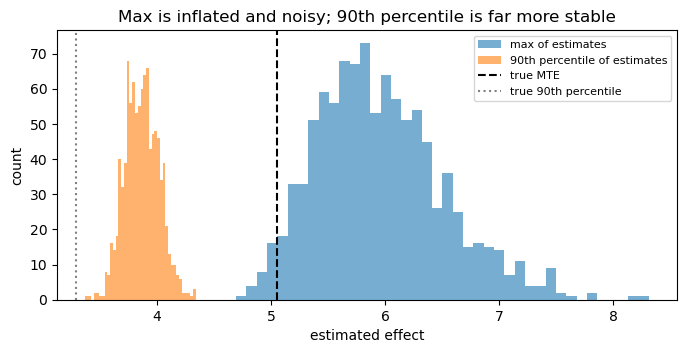

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(6)
n_items, n_reps = 200, 1000
noise_sd = 1.0                    # error in estimating each item's counterfactual

true_effect = rng.normal(2, 1, n_items)          # fixed true effect for each untreated item
true_mte = true_effect.max()                     # target: the biggest true effect
true_p90 = np.percentile(true_effect, 90)

max_est, p90_est = [], []
for _ in range(n_reps):
    # each repetition = a new noisy estimate of every item's counterfactual
    est_effect = true_effect + rng.normal(0, noise_sd, n_items)
    max_est.append(est_effect.max())
    p90_est.append(np.percentile(est_effect, 90))
max_est, p90_est = np.array(max_est), np.array(p90_est)

print(f"True MTE (max true effect):      {true_mte:.2f}")
print(f"True 90th percentile of effects: {true_p90:.2f}\n")
print(f"{'method':<22}{'mean':>7}{'target':>8}{'bias':>7}{'SD':>7}")
for name, est, target in [("max of estimates", max_est, true_mte),
                          ("90th pct of estimates", p90_est, true_p90)]:
    print(f"{name:<22}{est.mean():>7.2f}{target:>8.2f}{est.mean() - target:>+7.2f}{est.std():>7.2f}")

plt.figure(figsize=(8, 3.5))
plt.hist(max_est, bins=40, alpha=0.6, label='max of estimates')
plt.hist(p90_est, bins=40, alpha=0.6, label='90th percentile of estimates')
plt.axvline(true_mte, color='k', ls='--', label='true MTE')
plt.axvline(true_p90, color='gray', ls=':', label='true 90th percentile')
plt.xlabel('estimated effect'); plt.ylabel('count'); plt.legend(fontsize=8)
plt.title('Max is inflated and noisy; 90th percentile is far more stable')
plt.show()

My solution replaces the maximum estimated effect with the **90th percentile** of the estimated effects across all untreated items. The code works like this. It creates 200 untreated items, each with a fixed true treatment effect. In each of 1,000 repetitions, it estimates each item's counterfactual with noise (SD = 1), just as a real model would. Each repetition then records two summaries: the largest estimated effect (the original MTE method) and the 90th percentile of the estimated effects (my proposal). Because I know the true effects, I can measure how far off each method is on average (bias) and how much it jumps around between repetitions (SD).

The results show the problem from Question 1. The max of the estimates averages 5.96, while the true MTE is 5.05, so it overshoots by about 0.9. That's because the item that "wins" is usually one whose noise happened to be large and positive. The max is also unstable (SD = 0.56), because it depends on a single item. The 90th percentile is an order statistic in the middle of the upper tail, so it combines information from many items and no single lucky draw controls it. Its SD is 0.15, almost four times smaller.

The trade-off is that the 90th percentile answers a slightly different question: "what effect would a high-response item get?" rather than "what is the largest effect?" It is still a little inflated (+0.57), because noise spreads out the whole distribution of estimates. A further fix would be to first shrink each estimate toward the overall mean, based on how noisy it is, and then take the percentile. For a decision such as "which untreated items should we treat next?", a stable estimate for the top 10% is more useful than an unreliable estimate for the single best item.